# EDA: отзывы и размерное соответствие AI StyleLink

Ноутбук отвечает на шесть практических вопросов:

1. как устроен полный snapshot Wildberries;
2. насколько ручной Gold Standard репрезентативен;
3. согласованно ли размечены дополнительные признаки;
4. дают ли эти признаки диагностический прирост к простой текстовой модели;
5. чем отличаются тексты Wildberries и Яндекс Маркета;
6. как устроен размеченный внешний аудит Яндекс Маркета.

Анализ намеренно остаётся понятным и воспроизводимым: описательные статистики, простые графики, Cramér's V и одна групповая ablation-проверка.


## 1. Методика

EDA разделён на три уровня:

- полный snapshot описывает качество, пропуски и естественное распределение отзывов;
- общий текстовый EDA объединяет непустые отзывы WB и Яндекс Маркета, но всегда сохраняет `source` и показывает площадки отдельно;
- ручной Gold Standard используется для анализа targets, согласованности и размеченных признаков;
- 300 размеченных отзывов Яндекс Маркета рассматриваются отдельно как single-annotator external audit.

Machine-generated pseudo-labels анализируются отдельно и не считаются Gold Standard. Все model diagnostics используют групповые folds по `item_group_id`, чтобы отзывы одного товара не пересекали train и validation. Метки внешнего аудита не используются для изменения признаков, правил или выбора модели до основной оценки переноса.


In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import Image, Markdown, display

def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "research/data").exists() and (candidate / "docs/research").exists():
            return candidate
    raise RuntimeError("Не найден корень проекта ai-stylelink")

PROJECT_ROOT = find_project_root(Path.cwd().resolve())
sys.path.insert(0, str(PROJECT_ROOT))

from research.src.analysis.run_review_fit_eda import run_eda

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 140)
OUTPUT_DIR = PROJECT_ROOT / "research/outputs/eda/2026-10-24"
result = run_eda(output_dir=OUTPUT_DIR)
print(f"Проект: {PROJECT_ROOT}")
print(f"Результаты: {OUTPUT_DIR}")


Проект: /Users/am42saturday/Documents/Обучения/Мага 2025/Диплом/ai-stylelink
Результаты: /Users/am42saturday/Documents/Обучения/Мага 2025/Диплом/ai-stylelink/research/outputs/eda/2026-10-24


## 2. Загрузка и проверка единиц анализа


In [2]:
raw = result["raw"]
gold = result["gold"]
machine = result["machine"]
yandex_raw = result["yandex_raw"]
yandex_audit = result["yandex_audit"]

pd.DataFrame([
    {"dataset": "raw_wildberries", "rows": len(raw), "unique_reviews": raw.review_id.nunique(), "item_groups": raw.root_id.nunique()},
    {"dataset": "review_level_gold", "rows": len(gold), "unique_reviews": gold.review_id.nunique(), "item_groups": gold.item_group_id.nunique()},
    {"dataset": "machine_annotations", "rows": len(machine), "unique_reviews": machine.review_id.nunique(), "item_groups": machine.item_group_id.nunique()},
    {"dataset": "raw_yandex_market", "rows": len(yandex_raw), "unique_reviews": yandex_raw.review_id.nunique(), "item_groups": yandex_raw.product_group_id.nunique()},
    {"dataset": "yandex_market_external_audit", "rows": len(yandex_audit), "unique_reviews": yandex_audit.review_id.nunique(), "item_groups": yandex_audit.product_id.nunique()},
])


,dataset,rows,unique_reviews,item_groups
0,raw_wildberries,40474,40474,40
1,review_level_gold,1200,1200,40
2,machine_annotations,40474,40474,40
3,raw_yandex_market,646,646,6
4,yandex_market_external_audit,300,300,6


In [3]:
result["tables"]["full_data_summary"]


,metric,value
0,rows,40474.000000
1,unique_review_ids,40474.000000
2,duplicate_review_ids,0.000000
3,item_groups,40.000000
4,nm_ids,531.000000
5,reviews_with_text,27384.000000
6,reviews_without_text,13090.000000
7,reviews_with_ordered_size,40452.000000
8,reviews_with_fit_keyword,2979.000000
9,duplicate_nonempty_texts,2605.000000


### Выводы по этапу

- Ключ `review_id` уникален во всех 40 474 строках.
- Основная item-level единица — `root_id`/`item_group_id`; в snapshot всего 40 таких групп.
- 13 090 отзывов не имеют текста. Они не подаются text-модели, но сохраняются для расчёта Coverage.
- Повторяющиеся тексты существуют, поэтому при дальнейшем обучении полезно отдельно контролировать текстовые дубликаты внутри folds.


## 3. Длина текста и смещение ручной выборки


In [4]:
result["tables"]["text_length_comparison"]


,dataset,n,mean_words,median_words,p90_words,share_under_10_words
0,all_nonempty_wb,27384,11.159801,8.0,24.0,0.596589
1,manual_gold,1200,29.435000,24.0,49.0,0.000000


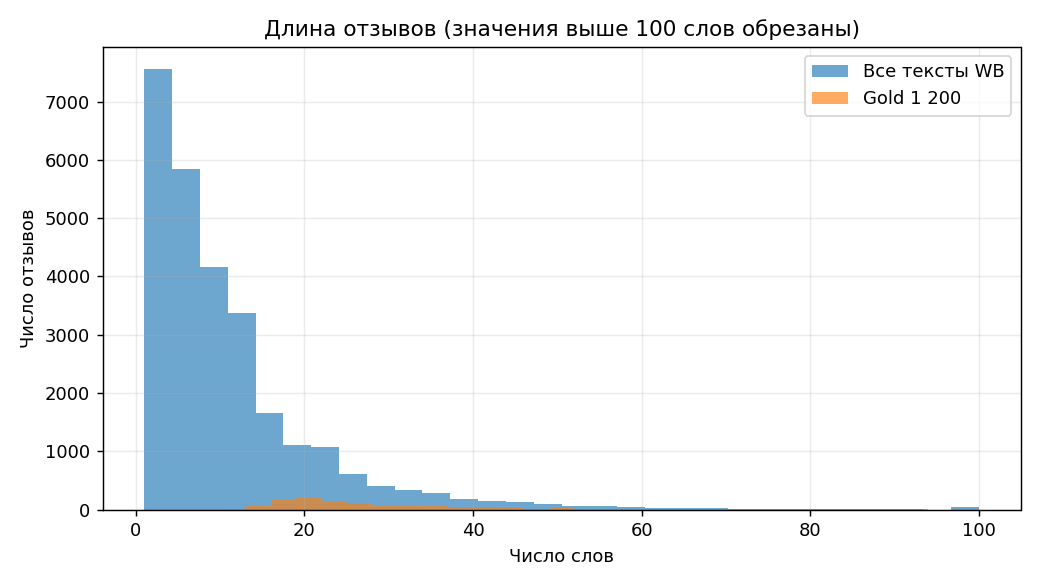

In [5]:
display(Image(filename=str(OUTPUT_DIR / "figures/01_text_length_comparison.png")))


In [6]:
result["tables"]["selection_bias"]


,dataset,n,fit_keyword_share,median_words,mean_rating
0,all_nonempty_wb,27384,0.108786,8.0,4.55883
1,manual_gold,1200,1.000000,24.0,4.65500


### Выводы по этапу

- В полном пуле медиана равна 8 словам, в ручном Gold Standard — 24 словам.
- Fit-keyword присутствует в 100% ручной выборки и только примерно в 10,9% полного пригодного пула.
- Поэтому текущие 1 200 строк подходят для разработки направления посадки, но завышают ожидаемое end-to-end качество обнаружения fit-сигнала.
- Автоматически удалять короткие отзывы нельзя: короткая фраза может содержать прямой сильный сигнал.


## 4. Распределение ручных targets


In [7]:
result["tables"]["gold_distribution"]


,field,value,count,share
0,fit_label,no_signal,449,0.374167
1,fit_label,true_to_size,352,0.293333
2,fit_label,runs_small,195,0.162500
3,fit_label,runs_large,204,0.170000
4,signal_explicitness,none,449,0.374167
5,signal_explicitness,implicit,345,0.287500
6,signal_explicitness,explicit,406,0.338333
7,informativeness,low,698,0.581667
8,informativeness,medium,232,0.193333
9,informativeness,high,270,0.225000


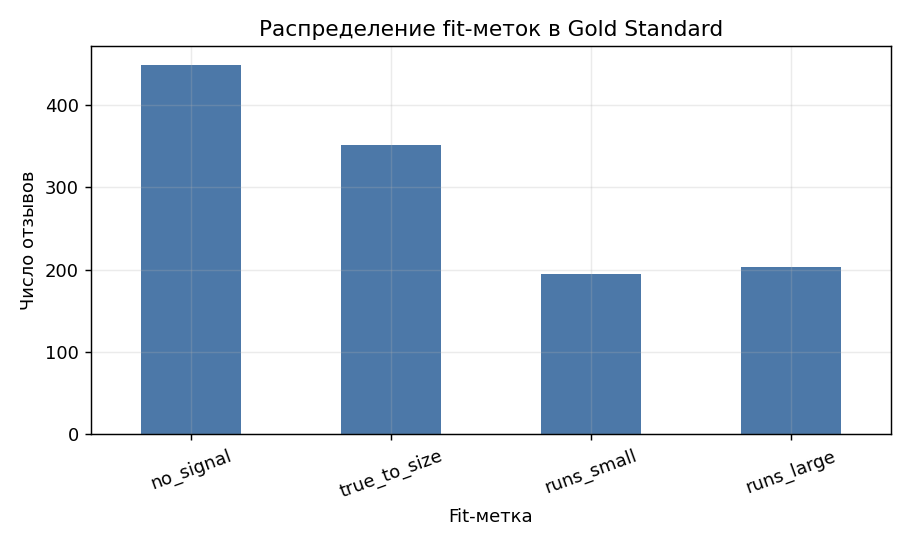

In [8]:
display(Image(filename=str(OUTPUT_DIR / "figures/02_gold_fit_distribution.png")))


### Выводы по этапу

- Все четыре fit-класса представлены, хотя `no_signal` является крупнейшим классом.
- 58,3% отзывов получили низкую информативность.
- Для модели нужны class weights или контролируемая стратификация, а качество следует показывать через Macro-F1, а не только Accuracy.


## 5. Согласованность разметчиков до adjudication


In [9]:
result["tables"]["annotation_agreement"]


,field,n_pairs,observed_agreement,cohens_kappa
0,fit_label,1200,0.704167,0.590740
1,signal_explicitness,1200,0.625833,0.432192
2,informativeness,1200,0.539167,0.289458
3,user_action,1198,0.409015,0.210286
4,internal_consistency,1196,0.857860,0.082400
5,body_parameters_exact_set,1198,0.775459,0.576293
6,fit_zones_exact_set,1200,0.755833,0.585604
7,signal_vs_no_signal,1200,0.792500,0.388707
8,fit_direction_both_signal,824,0.871359,0.798522
9,informativeness_quadratic,1197,0.540518,0.511391


### Выводы по этапу

- Четыре fit-метки имеют умеренную согласованность.
- После того как оба разметчика признали наличие сигнала, направление определяется заметно стабильнее.
- Самые проблемные признаки — действие пользователя, внутренняя согласованность и информативность.
- Значения рассчитаны до обсуждения расхождений; итоговый Gold Standard хранится отдельно.


## 6. Покрытие и описательная связь размеченных признаков


In [10]:
result["tables"]["feature_diagnostics"]


,feature,resolved_coverage,non_default_or_nonempty_share,n_states_including_unresolved,cramers_v_with_fit_label,pre_adjudication_kappa
0,signal_explicitness,1.000000,0.625833,3,0.708157,0.432192
1,informativeness,1.000000,0.418333,3,0.451469,0.289458
2,body_parameters,0.774167,0.175833,14,0.170900,0.576293
3,fit_zones,0.755833,0.221667,23,0.150116,0.585604
4,user_action,0.408333,0.141667,7,0.118617,0.210286
5,internal_consistency,0.855000,0.850833,4,0.067927,0.082400


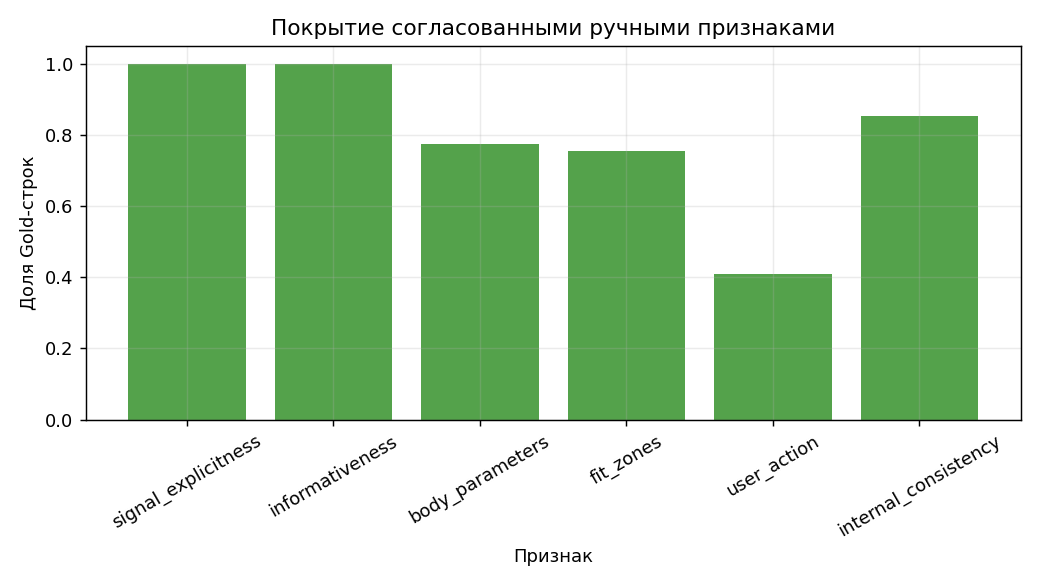

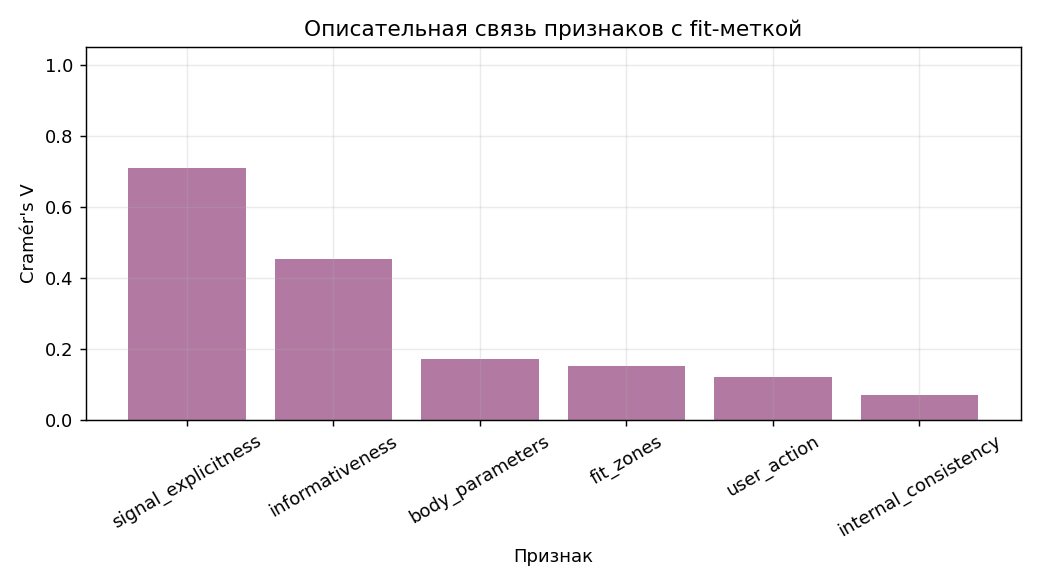

In [11]:
display(Image(filename=str(OUTPUT_DIR / "figures/04_auxiliary_feature_coverage.png")))
display(Image(filename=str(OUTPUT_DIR / "figures/05_feature_cramers_v.png")))


### Выводы по этапу

- `signal_explicitness` сильно связан с fit-меткой, но часть связи задана инструкцией: для `no_signal` обязательно используется `none`. Это не независимое доказательство полезности.
- `informativeness` показывает наиболее заметную нетривиальную связь с fit-классом, но её исходная Kappa остаётся низкой.
- Параметры тела и зоны посадки размечаются сравнительно устойчиво, однако встречаются нечасто и имеют слабую связь с общим fit-классом.
- Действие пользователя имеет низкое покрытие и низкую согласованность.
- Внутренняя согласованность почти не связана с fit-классом и в текущем виде не выглядит сильным основным признаком.


## 7. Простая ablation-проверка


In [12]:
result["tables"]["ablation_results"]


,model,accuracy,macro_f1,note
0,text_plus_informativeness,0.770833,0.751501,diagnostic upper bound; human auxiliary labels are not production inputs
1,text_plus_all_auxiliary,0.760833,0.739816,diagnostic upper bound; human auxiliary labels are not production inputs
2,text_only,0.697500,0.707535,text baseline
3,text_plus_action_and_consistency,0.688333,0.697069,diagnostic upper bound; human auxiliary labels are not production inputs
4,text_plus_body_and_zones,0.681667,0.686743,diagnostic upper bound; human auxiliary labels are not production inputs
5,auxiliary_only,0.527500,0.439289,diagnostic upper bound; human auxiliary labels are not production inputs


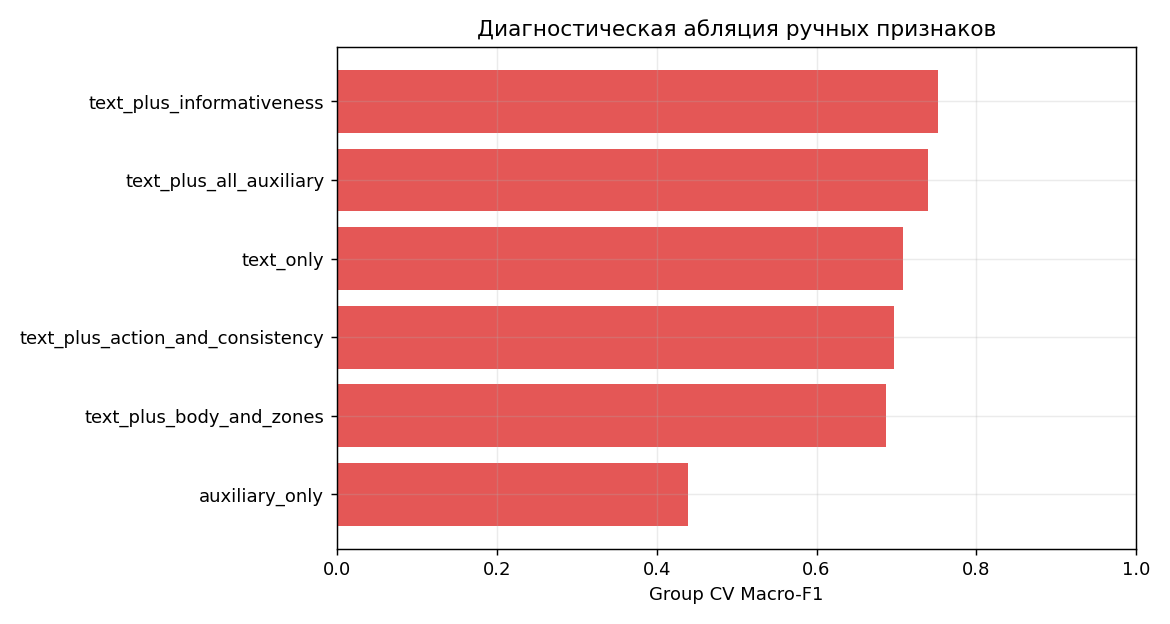

In [13]:
display(Image(filename=str(OUTPUT_DIR / "figures/06_ablation_macro_f1.png")))


### Выводы по этапу

- Простой text-only baseline получает Macro-F1 около 0,692.
- Добавление ручной информативности повышает диагностический результат примерно до 0,745.
- Параметры тела и зоны, а также действие и согласованность по отдельности не улучшают text baseline.
- Все дополнительные признаки вместе дают меньший результат, чем одна информативность.

Это **диагностическая верхняя оценка**: здесь используются ручные признаки. В production их сначала должна предсказать модель. Поэтому таблица поддерживает решение оставить информативность основной исследуемой переменной, но ещё не подтверждает item-level гипотезу.


## 8. Полная машинная разметка


In [14]:
result["tables"]["machine_distribution"]


,fit_label,count,share,mean_confidence,median_confidence
0,no_signal,24817,0.906259,0.935510,0.98
1,true_to_size,1681,0.061386,0.918104,0.92
2,runs_small,510,0.018624,0.914704,0.92
3,runs_large,376,0.013731,0.915403,0.92


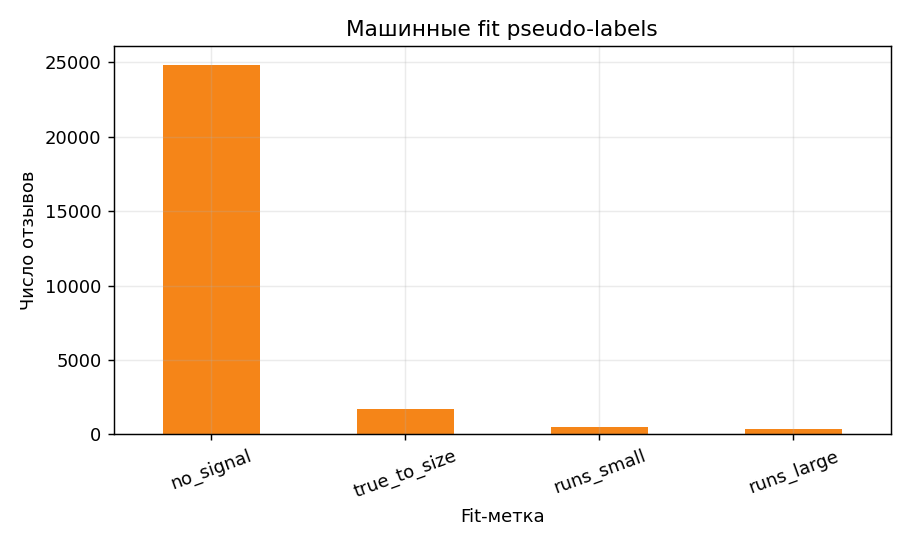

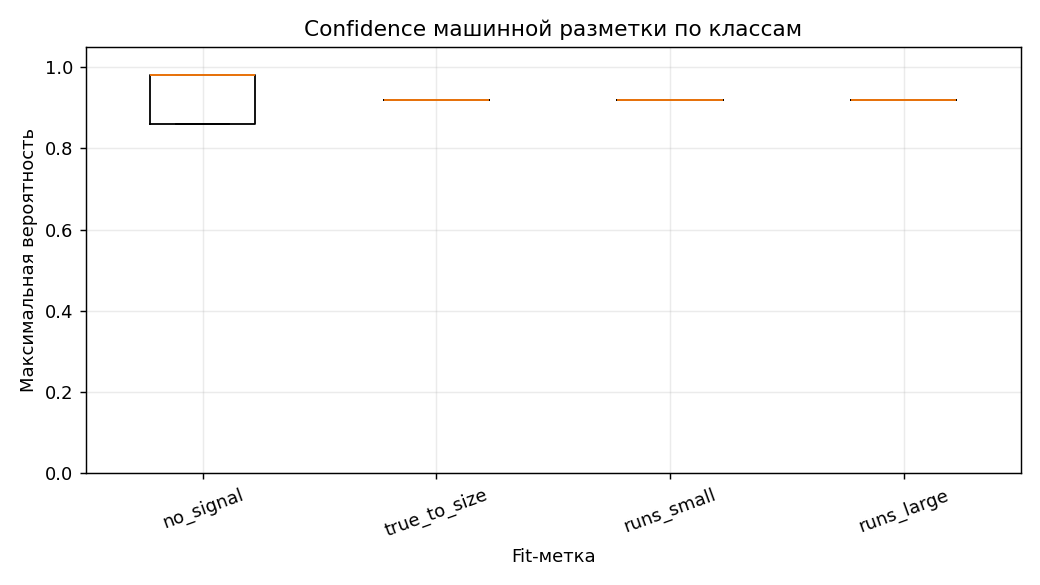

In [15]:
display(Image(filename=str(OUTPUT_DIR / "figures/03_machine_fit_distribution.png")))
display(Image(filename=str(OUTPUT_DIR / "figures/08_machine_confidence_by_label.png")))


### Выводы по этапу

- В полном текстовом пуле 90,6% отзывов получили `no_signal`.
- Это правдоподобно с учётом естественного потока отзывов, но confidence частично задаётся строгими правилами v4 и не является откалиброванной вероятностью.
- Machine labels можно использовать для exploratory aggregation, формирования hard cases и анализа покрытия, но не как финальный Gold Standard.


## 9. Wildberries и Яндекс Маркет: общий и сравнительный EDA


In [16]:
result["tables"]["combined_text_summary"]


,metric,value
0,nonempty_reviews,28030.000000
1,wildberries_reviews,27384.000000
2,yandex_market_reviews,646.000000
3,exact_duplicate_rows,2615.000000
4,exact_texts_shared_between_sources,0.000000
5,median_words,8.000000
6,mean_words,11.339922


In [17]:
result["tables"]["marketplace_text_summary"]


,source,nonempty_reviews,product_groups,mean_words,median_words,p90_words,shorter_than_10_words_share,ordered_size_coverage,common_fit_keyword_share,duplicate_text_share
0,wildberries,27384,40,11.159801,8.0,24.0,0.596589,0.999233,0.337533,0.095129
1,yandex_market,646,6,18.975232,14.0,39.0,0.323529,1.000000,0.393189,0.015480


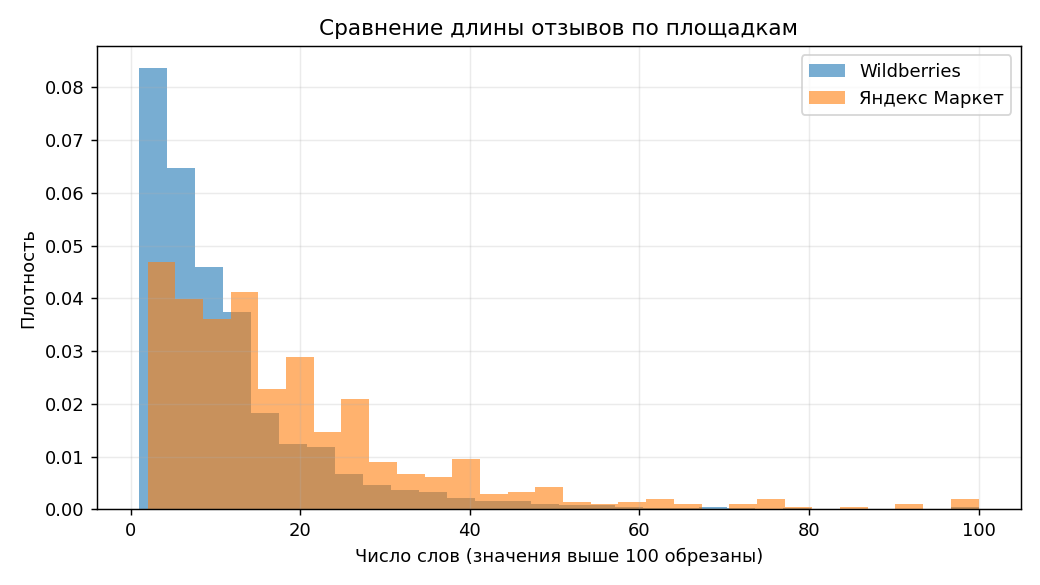

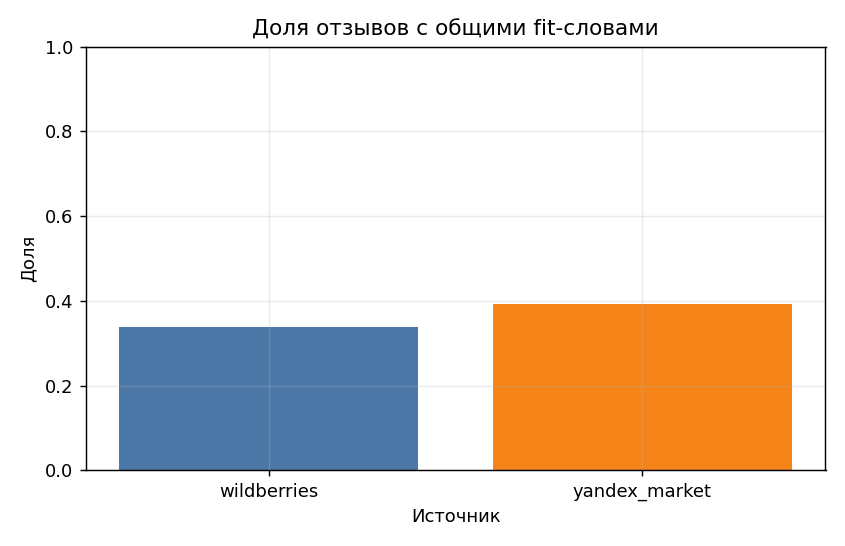

In [18]:
display(Image(filename=str(OUTPUT_DIR / "figures/09_marketplace_text_length.png")))
display(Image(filename=str(OUTPUT_DIR / "figures/11_marketplace_fit_keyword_share.png")))


### Выводы по этапу

- Общий текстовый EDA охватывает все непустые отзывы обеих площадок, но `source` сохраняется для каждой строки.
- Сравнение площадок обязательно: единая сводка скрывает различия длины текста, доли коротких отзывов и частоты fit-слов.
- Fit-словарь здесь используется только как одинаковый описательный индикатор и не заменяет ручную разметку.


### Яндекс Маркет по категориям


In [19]:
result["tables"]["yandex_category_summary"]


,category,reviews,products,median_words,mean_words,common_fit_keyword_share
0,jeans,164,1,10.0,14.829268,0.445122
3,sports_tshirt,157,1,17.0,21.528662,0.312102
2,outerwear,101,1,15.0,20.584158,0.227723
1,jumper,100,1,18.0,21.610000,0.500000
4,sweatshirt,85,1,12.0,16.035294,0.505882
5,trousers,39,1,12.0,21.615385,0.410256


Каждая из шести категорий Яндекс Маркета представлена одной карточкой. Поэтому различия категорий одновременно являются различиями конкретных товаров и не оценивают весь маркетплейс.


## 10. Размеченный внешний аудит Яндекс Маркета


In [20]:
result["tables"]["yandex_audit_distribution"]


,field,value,count,share
0,fit_label,no_signal,197,0.656667
1,fit_label,true_to_size,34,0.113333
2,fit_label,runs_small,37,0.123333
3,fit_label,runs_large,32,0.106667
4,signal_explicitness,none,197,0.656667
5,signal_explicitness,implicit,29,0.096667
6,signal_explicitness,explicit,74,0.246667
7,informativeness,low,242,0.806667
8,informativeness,medium,42,0.140000
9,informativeness,high,16,0.053333


In [21]:
result["tables"]["yandex_audit_by_stratum"]


,selection_stratum,reviews,signal_share,explicit_or_implicit_share,medium_or_high_informativeness_share,median_words
0,fit_keyword,89,0.898876,0.898876,0.370787,20.0
1,random_no_keyword,211,0.109005,0.109005,0.118483,14.0


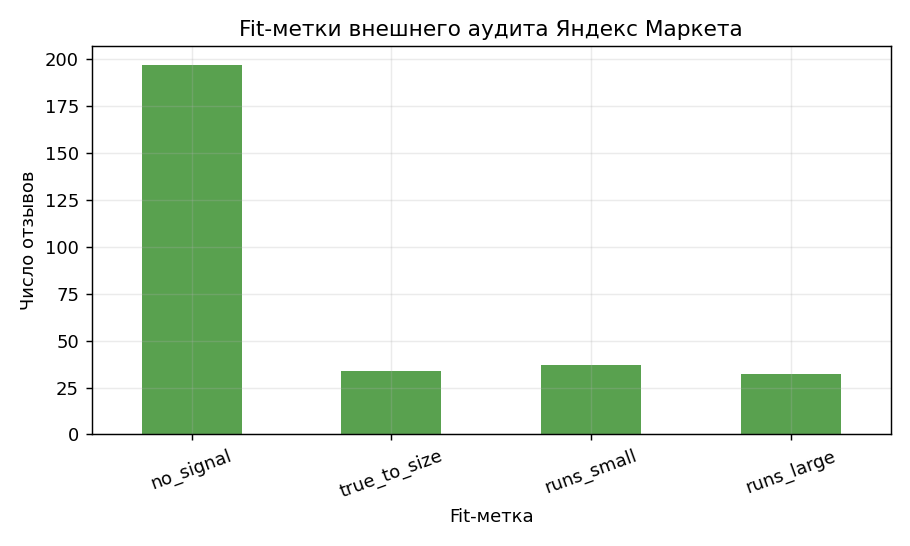

In [22]:
display(Image(filename=str(OUTPUT_DIR / "figures/10_yandex_audit_fit_distribution.png")))


### Выводы по этапу

- Все 300 строк размечены одним исследователем; Kappa и adjudication для этого набора не применяются.
- Внешний аудит хранится отдельно от development Gold Standard.
- Его метки не должны влиять на выбор признаков, правил и модели до фиксации основного протокола. После этого они используются для оценки переноса между площадками и анализа ошибок.


## 11. Число отзывов на товар


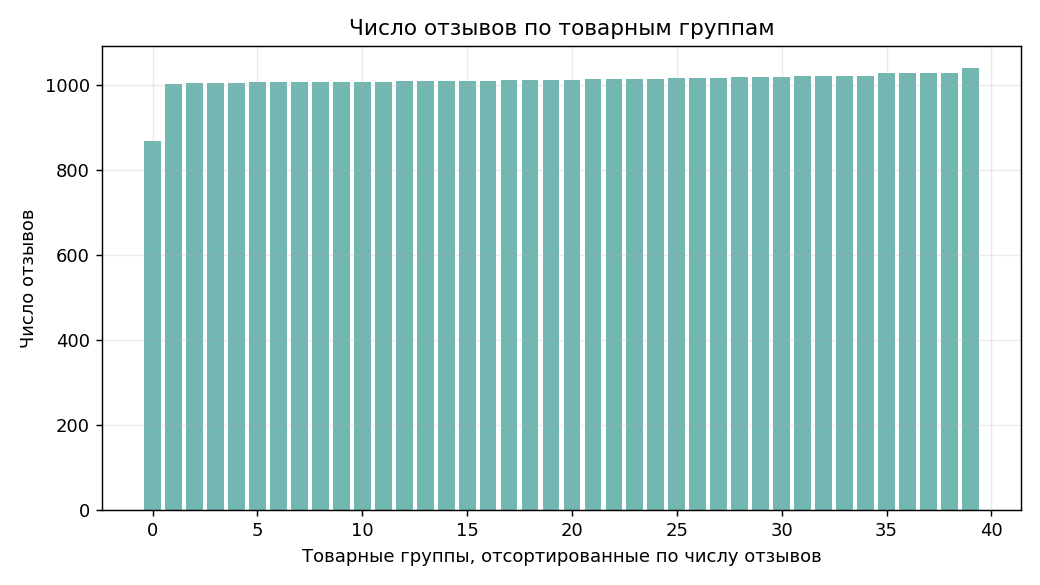

In [23]:
display(Image(filename=str(OUTPUT_DIR / "figures/07_reviews_per_item_group.png")))


### Выводы по этапу

Товарные группы различаются по числу отзывов, поэтому при item-level агрегации нельзя считать отдельные отзывы независимыми наблюдениями. Split, bootstrap и доверительные интервалы должны строиться по `item_group_id`.


## 12. Итоговые решения


1. Основным review-level target остаётся fit-класс, а информативность — главным кандидатом на вес при item-level агрегации.
2. Параметры тела, зоны, действие и согласованность не удаляются из схемы, но переносятся в дополнительные ablation-эксперименты.
3. Низкая Kappa информативности требует осторожной интерпретации и отдельной оценки её предиктора.
4. Текущие 40 товарных групп считаются development-корпусом.
5. Общий текстовый EDA включает WB и Яндекс Маркет, но все выводы также показываются отдельно по `source`.
6. Все 646 отзывов Яндекса используются для описательного анализа, а 300 размеченных строк остаются отдельным внешним аудитом.
7. Метки Яндекса не используются для настройки модели до фиксации review-level протокола.
8. Основная гипотеза будет проверяться сравнением equal-weight и informativeness-weighted aggregation на одинаковых review-level probabilities.


## 13. Полный автоматически сформированный отчёт


In [24]:
display(Markdown((OUTPUT_DIR / "EDA_REPORT.md").read_text(encoding="utf-8")))


# EDA AI StyleLink: отзывы и размерное соответствие

Дата анализа: 24 октября 2026 года.

## 1. Использованные данные

- полный snapshot Wildberries: 40,474 отзывов и 40 товарных групп;
- snapshot Яндекс Маркета: 646 непустых отзывов, 6 карточек и 6 категорий одежды;
- review-level Gold Standard: 1,200 отзывов;
- машинная разметка v4: 27,384 predictions и 13,090 пустых текстов.
- внешний аудит Яндекс Маркета: 300 отзывов с разметкой одного исследователя.

## 2. Качество и структура полного snapshot

| metric | value |
|---|---|
| rows | 40474.000 |
| unique_review_ids | 40474.000 |
| duplicate_review_ids | 0.000 |
| item_groups | 40.000 |
| nm_ids | 531.000 |
| reviews_with_text | 27384.000 |
| reviews_without_text | 13090.000 |
| reviews_with_ordered_size | 40452.000 |
| reviews_with_fit_keyword | 2979.000 |
| duplicate_nonempty_texts | 2605.000 |
| median_words_nonempty | 8.000 |
| mean_words_nonempty | 11.160 |

В данных не обнаружены дубликаты `review_id`. Пустые тексты составляют 32.3% snapshot и должны оставаться в знаменателе Coverage, но не подаваться текстовой модели. Медианная длина непустого отзыва — 8 слов.

## 3. Репрезентативность ручной разметки

| dataset | n | fit_keyword_share | median_words | mean_rating |
|---|---|---|---|---|
| all_nonempty_wb | 27384 | 0.109 | 8.000 | 4.559 |
| manual_gold | 1200 | 1.000 | 24.000 | 4.655 |

Ручной Gold Standard существенно длиннее полного пула: медиана 24 против 8 слов. Доля fit-keyword составляет 100.0% против 10.9%. Поэтому текущие 1 200 строк подходят для разработки классификатора направления, но не дают несмещённой end-to-end оценки обнаружения fit-сигнала.

## 4. Распределение ручных меток

| field | value | count | share |
|---|---|---|---|
| fit_label | no_signal | 449 | 0.374 |
| fit_label | true_to_size | 352 | 0.293 |
| fit_label | runs_small | 195 | 0.163 |
| fit_label | runs_large | 204 | 0.170 |
| signal_explicitness | none | 449 | 0.374 |
| signal_explicitness | implicit | 345 | 0.287 |
| signal_explicitness | explicit | 406 | 0.338 |
| informativeness | low | 698 | 0.582 |
| informativeness | medium | 232 | 0.193 |
| informativeness | high | 270 | 0.225 |

## 5. Согласованность разметки до adjudication

| field | n_pairs | observed_agreement | cohens_kappa |
|---|---|---|---|
| fit_label | 1200 | 0.704 | 0.591 |
| signal_explicitness | 1200 | 0.626 | 0.432 |
| informativeness | 1200 | 0.539 | 0.289 |
| user_action | 1198 | 0.409 | 0.210 |
| internal_consistency | 1196 | 0.858 | 0.082 |
| body_parameters_exact_set | 1198 | 0.775 | 0.576 |
| fit_zones_exact_set | 1200 | 0.756 | 0.586 |
| signal_vs_no_signal | 1200 | 0.792 | 0.389 |
| fit_direction_both_signal | 824 | 0.871 | 0.799 |
| informativeness_quadratic | 1197 | 0.541 | 0.511 |

Направление посадки при наличии сигнала размечается заметно стабильнее, чем граница `signal/no_signal`, действие пользователя, внутренняя согласованность и информативность. Это объясняет необходимость v4 и отдельного хранения исходных ответов.

## 6. Диагностика размеченных признаков

| feature | resolved_coverage | non_default_or_nonempty_share | n_states_including_unresolved | cramers_v_with_fit_label | pre_adjudication_kappa |
|---|---|---|---|---|---|
| signal_explicitness | 1.000 | 0.626 | 3 | 0.708 | 0.432 |
| informativeness | 1.000 | 0.418 | 3 | 0.451 | 0.289 |
| body_parameters | 0.774 | 0.176 | 14 | 0.171 | 0.576 |
| fit_zones | 0.756 | 0.222 | 23 | 0.150 | 0.586 |
| user_action | 0.408 | 0.142 | 7 | 0.119 | 0.210 |
| internal_consistency | 0.855 | 0.851 | 4 | 0.068 | 0.082 |

Cramér's V здесь является описательной связью, а не доказательством причинности или полезности в продуктовой модели. Для `signal_explicitness` высокая связь частично задана самой инструкцией: при `no_signal` обязательно ставится `none`.

## 7. Простая абляция

| model | accuracy | macro_f1 | note |
|---|---|---|---|
| text_plus_informativeness | 0.771 | 0.752 | diagnostic upper bound; human auxiliary labels are not production inputs |
| text_plus_all_auxiliary | 0.761 | 0.740 | diagnostic upper bound; human auxiliary labels are not production inputs |
| text_only | 0.698 | 0.708 | text baseline |
| text_plus_action_and_consistency | 0.688 | 0.697 | diagnostic upper bound; human auxiliary labels are not production inputs |
| text_plus_body_and_zones | 0.682 | 0.687 | diagnostic upper bound; human auxiliary labels are not production inputs |
| auxiliary_only | 0.527 | 0.439 | diagnostic upper bound; human auxiliary labels are not production inputs |

Лучшая диагностическая конфигурация — `text_plus_informativeness` с Macro-F1 0.752. Это верхняя оценка: дополнительные признаки взяты из ручной разметки и в реальном inference должны сначала предсказываться. Основную гипотезу об информативности эта таблица не проверяет — для неё требуется item-level сравнение одинаковых review-level predictions с равными и различными весами.

## 8. Машинные pseudo-labels

| fit_label | count | share | mean_confidence | median_confidence |
|---|---|---|---|---|
| no_signal | 24817 | 0.906 | 0.936 | 0.980 |
| true_to_size | 1681 | 0.061 | 0.918 | 0.920 |
| runs_small | 510 | 0.019 | 0.915 | 0.920 |
| runs_large | 376 | 0.014 | 0.915 | 0.920 |

Среди текстовых отзывов `no_signal` занимает 90.6%. Эти значения полезны для exploratory aggregation и формирования hard cases, но не являются Gold Standard.

## 9. Сравнение Wildberries и Яндекс Маркета

| source | nonempty_reviews | product_groups | mean_words | median_words | p90_words | shorter_than_10_words_share | ordered_size_coverage | common_fit_keyword_share | duplicate_text_share |
|---|---|---|---|---|---|---|---|---|---|
| wildberries | 27384 | 40 | 11.160 | 8.000 | 24.000 | 0.597 | 0.999 | 0.338 | 0.095 |
| yandex_market | 646 | 6 | 18.975 | 14.000 | 39.000 | 0.324 | 1.000 | 0.393 | 0.015 |

Общий текстовый корпус содержит 28,030 непустых отзывов, но источник сохраняется для каждой строки. Медиана длины составляет 8 слов для Wildberries и 14 слов для Яндекс Маркета. Доля текстов короче 10 слов — 59.7% и 32.4% соответственно. Это показывает domain shift по форме текста; сводная статистика без разбивки по площадкам скрыла бы различия.

Единый простой словарь fit-упоминаний применяется к обеим площадкам только как EDA-индикатор, а не как разметка или target. Он встречается в 33.8% текстов Wildberries и 39.3% текстов Яндекс Маркета.

### Яндекс Маркет по категориям

| category | reviews | products | median_words | mean_words | common_fit_keyword_share |
|---|---|---|---|---|---|
| jeans | 164 | 1 | 10.000 | 14.829 | 0.445 |
| sports_tshirt | 157 | 1 | 17.000 | 21.529 | 0.312 |
| outerwear | 101 | 1 | 15.000 | 20.584 | 0.228 |
| jumper | 100 | 1 | 18.000 | 21.610 | 0.500 |
| sweatshirt | 85 | 1 | 12.000 | 16.035 | 0.506 |
| trousers | 39 | 1 | 12.000 | 21.615 | 0.410 |

Пул Яндекс Маркета ограничен шестью карточками: каждая категория представлена одной карточкой. Поэтому различия категорий нельзя отделить от различий конкретных товаров, а найденные доли нельзя переносить на весь маркетплейс.

## 10. Размеченный внешний аудит Яндекс Маркета

| field | value | count | share |
|---|---|---|---|
| fit_label | no_signal | 197 | 0.657 |
| fit_label | true_to_size | 34 | 0.113 |
| fit_label | runs_small | 37 | 0.123 |
| fit_label | runs_large | 32 | 0.107 |
| signal_explicitness | none | 197 | 0.657 |
| signal_explicitness | implicit | 29 | 0.097 |
| signal_explicitness | explicit | 74 | 0.247 |
| informativeness | low | 242 | 0.807 |
| informativeness | medium | 42 | 0.140 |
| informativeness | high | 16 | 0.053 |

### По стратам отбора

| selection_stratum | reviews | signal_share | explicit_or_implicit_share | medium_or_high_informativeness_share | median_words |
|---|---|---|---|---|---|
| fit_keyword | 89 | 0.899 | 0.899 | 0.371 | 20.000 |
| random_no_keyword | 211 | 0.109 | 0.109 | 0.118 | 14.000 |

Внешний аудит содержит 197 `no_signal`, 34 `true_to_size`, 37 `runs_small` и 32 `runs_large`. Это single-annotator audit: Cohen's Kappa и adjudication к нему не применяются. Его метки не используются для переопределения признаков или выбора модели до основной внешней оценки; после фиксации модели они применяются для проверки переноса и анализа ошибок.

## 11. Решения после EDA

1. Сохранять короткие отзывы: минимальная длина текста не является фильтром качества fit-сигнала.
2. Считать текущие 40 товарных групп development-корпусом и использовать group folds без пересечения `item_group_id`.
3. Не делать вывод о полезности признака только по Cramér's V; подтверждать его одинаковой group-CV абляцией.
4. `signal_explicitness` не использовать как независимое доказательство fit-класса, поскольку часть связи задана правилами разметки.
5. Информативность сохранить как главный исследуемый вес, но учитывать её низкую исходную Kappa и диагностическое качество предиктора.
6. Общий текстовый EDA проводить на WB и Яндекс Маркете совместно, но всегда сохранять поле источника и показывать сравнение площадок отдельно.
7. Все 646 отзывов Яндекс Маркета использовать только для описательной статистики текста; 300 размеченных строк хранить отдельно как внешний аудит.
8. Не использовать метки внешнего аудита для изменения признаков, правил или выбора модели до фиксации основного review-level протокола.
9. После фиксации модели рассчитать на 300 строках Яндекса метрики переноса, confidence/calibration и error analysis.
